# Fitting RealNVP and cRealNVP to distribution functions

In this notebook, RealNVP and cRealNVP learn **analytically known distributions** from samples.
Because the exact density is known, the quality of the fit can be verified directly. In contrast to the VAE,
a normalizing flow provides an **exact `log_prob`**, so the learned density itself can be compared with the exact one
(not only samples): density plots, log-likelihood on test data, and a Kullback-Leibler estimate `KL(p ‖ q)`.

| Section | Model | Target Distribution |
|---|---|---|
| 3 | RealNVP | 2D-Gaussian-Mixture `p(x)` |
| 4 | RealNVP | 3D-Gaussian-Velocity-Distribution `p(v)` (Magnitude: Maxwell-Distribution) |
| 5 | cRealNVP | Maxwell-Distribution with temperature as condition `p(v \| T)` |
| 6 | RealNVP | Influence of the number of coupling layers `n_coupling` |
| 7 | RealNVP / cRealNVP | Invertibility, storage and loading |

Units: `m = k_B = 1`, so `σ² = T` and `v ~ N(0, T·I)`.

> **Disclaimer:** The models in this notebook are illustrative examples, not optimized results. Architectures, hyperparameters and training settings were chosen to keep the runtime short, not to reach maximum accuracy. The reported accuracies are therefore not the best achievable with this approach; there is most likely considerable room for improvement, e.g. through tuning of the number of coupling layers, network size, learning rate (schedule), batch size and number of epochs.

> **Requirements:** `scipy` (exact densities, KS test) and `matplotlib`.

## 1. Setup

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from scipy import stats
from scipy.special import logsumexp

from neuraldist.generative_model.registry import build_model
import neuraldist.generative_model.realnvp  # Import registers "realnvp" and "crealnvp"
from neuraldist.training import fit_model

tf.keras.utils.set_random_seed(0)
rng = np.random.default_rng(0)

# large batches and a higher learning rate keep the training in this notebook fast
FIT = dict(batch_size=512, learning_rate=2e-3)

## 2. Helperfunctions

In [2]:
def plot_history(history, title):
    fig, ax = plt.subplots(figsize=(5, 2.8))
    ax.plot(history.history["loss"])
    ax.set(title=f"{title}: negative log-likelihood", xlabel="Epoch")
    fig.tight_layout()
    plt.show()


def ks_statistic(samples, cdf):
    """Kolmogorov-Smirnov-Distance between samples and exact CDF (0 = perfect)."""
    return stats.kstest(samples, cdf).statistic


def kl_estimate(logp_exact, logq_model):
    """Monte-Carlo estimate of KL(p || q) from samples x ~ p (0 = perfect)."""
    return float(np.mean(logp_exact - logq_model))

## 3. RealNVP: 2D-Gaussian-Mixture

Three components with different weights and covariances. The exact density is the weighted sum of the individual densities.
The flow is trained on 30,000 samples and evaluated on **separate** test samples.

In [3]:
weights = np.array([0.3, 0.4, 0.3])
means = np.array([[-2.0, -1.0], [2.0, -1.0], [0.0, 2.0]])
covs = np.array([[[0.30, 0.15], [0.15, 0.25]],
                 [[0.40, -0.10], [-0.10, 0.20]],
                 [[0.15, 0.00], [0.00, 0.35]]])


def sample_mixture(n):
    comp = rng.choice(len(weights), size=n, p=weights)
    x = np.stack([rng.multivariate_normal(means[k], covs[k]) for k in comp])
    return x.astype("float32")


def mixture_logpdf(x):
    return logsumexp([np.log(w) + stats.multivariate_normal(m, c).logpdf(x)
                      for w, m, c in zip(weights, means, covs)], axis=0)


def mixture_marginal_cdf(x1):
    """CDF of the x₁ marginal distribution (mixture of 1D normal distributions)."""
    return sum(w * stats.norm(m[0], np.sqrt(c[0, 0])).cdf(x1) for w, m, c in zip(weights, means, covs))


x_gm = sample_mixture(30_000)
x_gm_test = sample_mixture(10_000)
print("Training data:", x_gm.shape, "| test data:", x_gm_test.shape)

Training data: (30000, 2) | test data: (10000, 2)


{'loss': 2.5301}


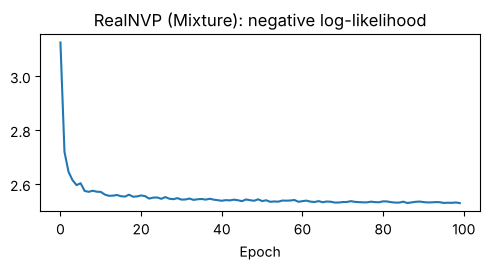

In [4]:
flow_gm = build_model("realnvp", x_dim=2, n_coupling=8)
history = fit_model(flow_gm, x_gm, epochs=100, **FIT)
print({k: round(v[-1], 4) for k, v in history.history.items()})
plot_history(history, "RealNVP (Mixture)")

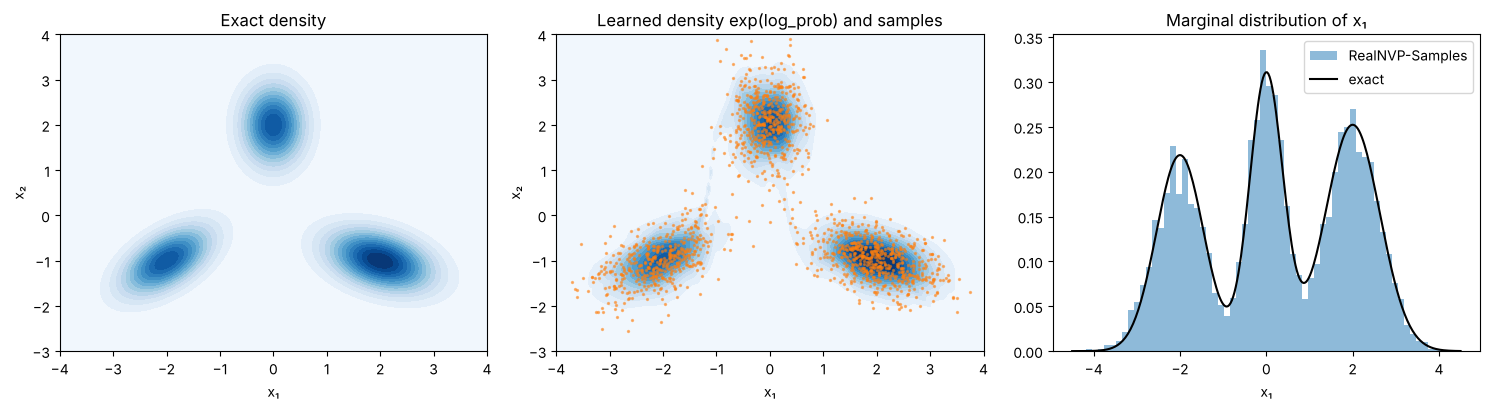

Mean log-likelihood on test data: exact -2.517 | RealNVP -2.542
KL(p || q) estimate:              0.0249
KS distance of the x₁ marginal distribution: 0.013
Component weights ~ Percentage of samples near the mean values:
  Component 0: Samples 0.24 | Training data 0.25
  Component 1: Samples 0.33 | Training data 0.33
  Component 2: Samples 0.26 | Training data 0.26


In [5]:
# exact vs. learned density on a grid (log_prob of the flow, no sampling needed)
gx, gy = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-3, 4, 200))
xy_grid = np.dstack([gx, gy]).reshape(-1, 2).astype("float32")
density_exact = np.exp(mixture_logpdf(xy_grid)).reshape(gx.shape)
density_flow = np.exp(flow_gm.log_prob(xy_grid).numpy()).reshape(gx.shape)
levels = np.linspace(0, density_exact.max(), 16)

samples_gm = flow_gm.sample(10_000).numpy()          # unconditional: (n_samples, x_dim)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].contourf(gx, gy, density_exact, levels=levels, cmap="Blues")
axes[0].set(title="Exact density", xlabel="x₁", ylabel="x₂")
axes[1].contourf(gx, gy, np.minimum(density_flow, levels[-1]), levels=levels, cmap="Blues")  # clip peaks above the colour scale
axes[1].scatter(samples_gm[:1500, 0], samples_gm[:1500, 1], s=2, color="tab:orange", alpha=0.5)
axes[1].set(title="Learned density exp(log_prob) and samples", xlabel="x₁", ylabel="x₂", xlim=(-4, 4), ylim=(-3, 4))

grid1 = np.linspace(-4.5, 4.5, 300)
marg = sum(w * stats.norm(m[0], np.sqrt(c[0, 0])).pdf(grid1) for w, m, c in zip(weights, means, covs))
axes[2].hist(samples_gm[:, 0], bins=60, density=True, alpha=0.5, label="RealNVP-Samples")
axes[2].plot(grid1, marg, "k", label="exact")
axes[2].set(title="Marginal distribution of x₁", xlabel="x₁")
axes[2].legend()
fig.tight_layout()
plt.show()

logp_exact = mixture_logpdf(x_gm_test)
logq_flow = flow_gm.log_prob(x_gm_test).numpy()
print(f"Mean log-likelihood on test data: exact {logp_exact.mean():.3f} | RealNVP {logq_flow.mean():.3f}")
print(f"KL(p || q) estimate:              {kl_estimate(logp_exact, logq_flow):.4f}")
print(f"KS distance of the x₁ marginal distribution: {ks_statistic(samples_gm[:, 0], mixture_marginal_cdf):.3f}")
print("Component weights ~ Percentage of samples near the mean values:")
for k, m in enumerate(means):
    frac = (np.linalg.norm(samples_gm - m, axis=1) < 1.0).mean()
    frac_true = (np.linalg.norm(x_gm - m, axis=1) < 1.0).mean()
    print(f"  Component {k}: Samples {frac:.2f} | Training data {frac_true:.2f}")

**Observation:** The flow reproduces the three components with the correct weights (KL ≈ 0.025) and, unlike a VAE, provides the density itself via `log_prob`. Faint low-density bridges between the components remain visible: a flow is a continuous bijection of a single-peaked Gaussian, so it has to connect separated modes. More coupling layers or epochs reduce this artefact but cannot remove it completely. The settings here are not tuned, so the KL value is not the best achievable.

## 4. RealNVP: 3D-Gaussian-Velocity-Distribution

The velocity components are independently normally distributed, `v ~ N(0, σ²·I)`, where `σ = 1`.
The **magnitude** `|v|` is then Maxwell-distributed, `f(v) = √(2/π) · v²/σ³ · exp(-v²/2σ²)`.
The flow learns `v` (3D); in addition to the derived magnitude distribution, the **log-density of each test point**
is compared with the exact one.

{'loss': 4.2598}


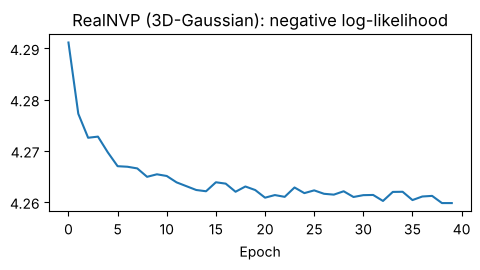

In [6]:
sigma = 1.0
v = rng.normal(0.0, sigma, size=(30_000, 3)).astype("float32")
v_test = rng.normal(0.0, sigma, size=(10_000, 3)).astype("float32")

flow_mw = build_model("realnvp", x_dim=3)
history = fit_model(flow_mw, v, epochs=40, **FIT)
print({k: round(val[-1], 4) for k, val in history.history.items()})
plot_history(history, "RealNVP (3D-Gaussian)")

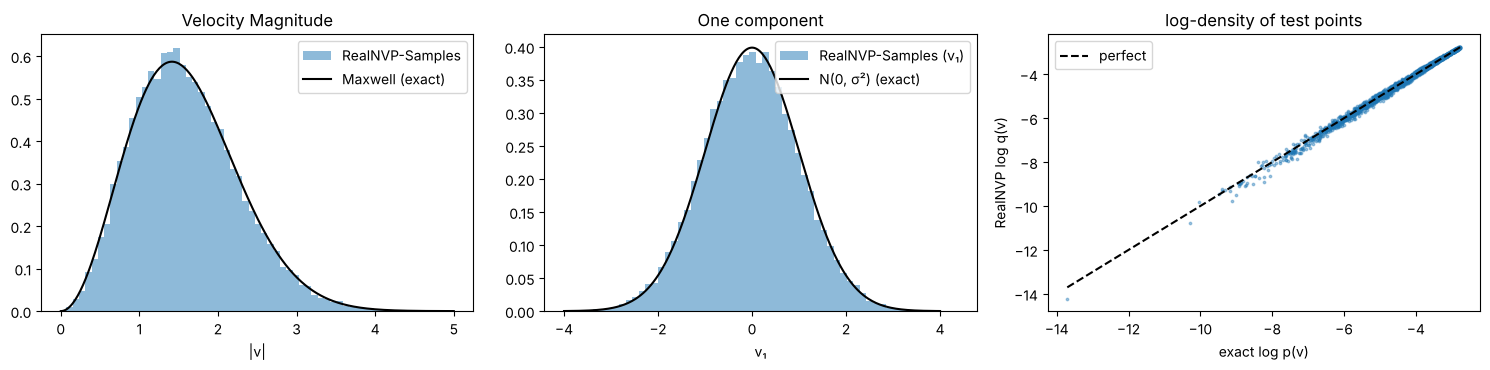

Standard deviation per component (target 1.0): [1.012 0.97  0.999]
Mean speed: Samples 1.589 | exact 1.596
KS distance of the magnitude:   0.009
KL(p || q) estimate:            0.0030


In [7]:
samples_v = flow_mw.sample(20_000).numpy()
speed = np.linalg.norm(samples_v, axis=1)

maxwell = stats.maxwell(scale=sigma)
vs = np.linspace(0, 5, 300)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(speed, bins=60, density=True, alpha=0.5, label="RealNVP-Samples")
axes[0].plot(vs, maxwell.pdf(vs), "k", label="Maxwell (exact)")
axes[0].set(title="Velocity Magnitude", xlabel="|v|")
axes[0].legend()

v_axis = np.linspace(-4, 4, 300)
axes[1].hist(samples_v[:, 0], bins=60, density=True, alpha=0.5, label="RealNVP-Samples (v₁)")
axes[1].plot(v_axis, stats.norm(0, sigma).pdf(v_axis), "k", label="N(0, σ²) (exact)")
axes[1].set(title="One component", xlabel="v₁")
axes[1].legend()

logp_exact = stats.multivariate_normal(np.zeros(3), sigma**2 * np.eye(3)).logpdf(v_test)
logq_flow = flow_mw.log_prob(v_test).numpy()
axes[2].scatter(logp_exact[:3000], logq_flow[:3000], s=3, alpha=0.4)
lims = [logp_exact.min(), logp_exact.max()]
axes[2].plot(lims, lims, "k--", label="perfect")
axes[2].set(title="log-density of test points", xlabel="exact log p(v)", ylabel="RealNVP log q(v)")
axes[2].legend()
fig.tight_layout()
plt.show()

print(f"Standard deviation per component (target {sigma}):", samples_v.std(0).round(3))
print(f"Mean speed: Samples {speed.mean():.3f} | exact {maxwell.mean():.3f}")
print(f"KS distance of the magnitude:   {ks_statistic(speed, maxwell.cdf):.3f}")
print(f"KL(p || q) estimate:            {kl_estimate(logp_exact, logq_flow):.4f}")

**Observation:** The Gaussian velocity distribution is fitted almost perfectly (KL ≈ 0.003, KS of the magnitude ≈ 0.01), and the log-densities of the test points lie on the diagonal. The flow keeps the correct width, which the VAE only achieved with a small `kl_weight`.

## 5. cRealNVP: Temperature dependent Maxwell Distribution

Now the temperature is the condition `c = T ∈ [0.5, 2]`, and `v | T ~ N(0, T·I)` holds.
The model is supposed to learn a **single** distribution that scales correctly with `T`.

The dataset provides `(v, T)` pairs; `build_model("crealnvp", ..., cond_dim=1)` builds the conditional model.
Every coupling network receives the temperature as additional input.

{'loss': 4.4877}


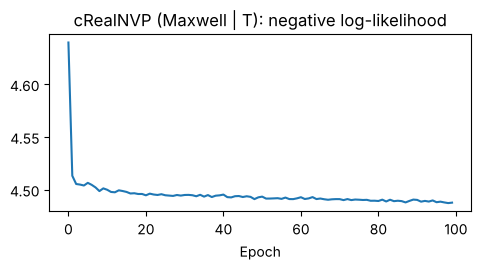

In [5]:
n = 30_000
T_train = rng.uniform(0.5, 2.0, size=(n, 1)).astype("float32")
v_train = (rng.standard_normal((n, 3)) * np.sqrt(T_train)).astype("float32")

crealnvp = build_model("crealnvp", x_dim=3, cond_dim=1)
history = fit_model(crealnvp, v_train, T_train, epochs=100, **FIT)
print({k: round(val[-1], 4) for k, val in history.history.items()})
plot_history(history, "cRealNVP (Maxwell | T)")

### Conditional Sampling and Conditional Density for multiple temperatures

`sample(n_samples, cond)` where `cond` is of the form `(B, 1)` returns `(B, n_samples, 3)`: `n_samples` samples **per temperature**.
`log_prob(v, T)` evaluates the conditional density `log q(v | T)`.

cond: (3, 1) -> samples: (3, 20000, 3)


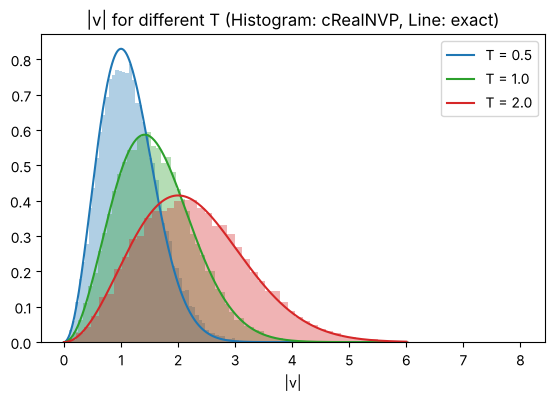

 T  | σ_samples/σ_exact | KS-Distance | KL(p || q)
0.5 |             1.039 |       0.034 | 0.0222
1.0 |             1.004 |       0.007 | 0.0096
2.0 |             1.014 |       0.019 | 0.0105


In [6]:
temps = np.array([[0.5], [1.0], [2.0]], dtype="float32")
samples_T = crealnvp.sample(20_000, cond=temps).numpy()
print("cond:", temps.shape, "-> samples:", samples_T.shape)

fig, ax = plt.subplots(figsize=(6.5, 4))
vs = np.linspace(0, 6, 300)
rows = []
for T, s, color in zip(temps[:, 0], samples_T, ["tab:blue", "tab:green", "tab:red"]):
    sp = np.linalg.norm(s, axis=1)
    exact = stats.maxwell(scale=np.sqrt(T))
    ax.hist(sp, bins=60, density=True, alpha=0.35, color=color)
    ax.plot(vs, exact.pdf(vs), color=color, label=f"T = {T:.1f}")

    # KL(p || q) for this temperature from fresh exact samples
    v_T = (rng.standard_normal((10_000, 3)) * np.sqrt(T)).astype("float32")
    logp = -0.5 * (v_T**2).sum(axis=1) / T - 1.5 * np.log(2 * np.pi * T)
    logq = crealnvp.log_prob(v_T, np.full((len(v_T), 1), T, dtype="float32")).numpy()
    rows.append((T, s.std(0).mean() / np.sqrt(T), ks_statistic(sp, exact.cdf), kl_estimate(logp, logq)))
ax.set(title="|v| for different T (Histogram: cRealNVP, Line: exact)", xlabel="|v|")
ax.legend()
plt.show()

print(" T  | σ_samples/σ_exact | KS-Distance | KL(p || q)")
for T, ratio, ks, kl in rows:
    print(f"{T:.1f} | {ratio:17.3f} | {ks:11.3f} | {kl:.4f}")

**Observation:** One conditional flow covers all temperatures: the width scales with `√T` within about 4 % (KL ≈ 0.01–0.02). The largest deviations occur at the edge of the training range (`T = 0.5`). With longer training or a larger model the accuracy, especially at the edges of the range, can most likely be increased further.

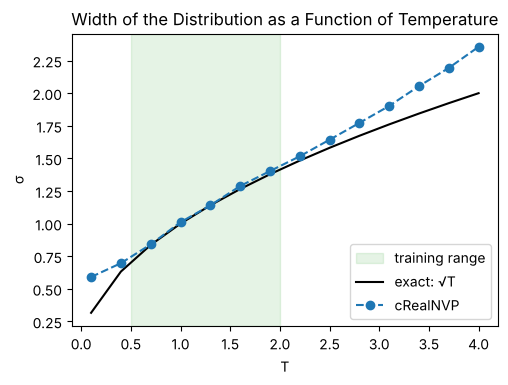

In [7]:
# Scaling of the standard deviation inside and outside the training range [0.5, 2]
T_grid = np.linspace(0.1, 4.0, 14, dtype="float32")[:, None]
s_grid = crealnvp.sample(5000, cond=T_grid).numpy()          # (14, 5000, 3)
sigma_model = s_grid.std(axis=1).mean(axis=1)

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.axvspan(0.5, 2.0, color="tab:green", alpha=0.12, label="training range")
ax.plot(T_grid[:, 0], np.sqrt(T_grid[:, 0]), "k", label="exact: √T")
ax.plot(T_grid[:, 0], sigma_model, "o--", label="cRealNVP")
ax.set(title="Width of the Distribution as a Function of Temperature", xlabel="T", ylabel="σ")
ax.legend()
plt.show()

**Observation:** Inside the training range the width follows `√T` closely. Outside the range the flow **does not extrapolate** correctly (too wide at `T = 0.1` and at `T = 4`). A conditional flow is only reliable where there is training data for the condition; physical constraints (such as the DB loss) can help beyond it.

## 6. Influence of the number of coupling layers `n_coupling`

A single coupling layer transforms only part of the dimensions, so several layers are needed to model
dependencies between all components and **multimodal** densities such as the mixture of Section 3.
Too few layers cannot separate the components of the mixture.

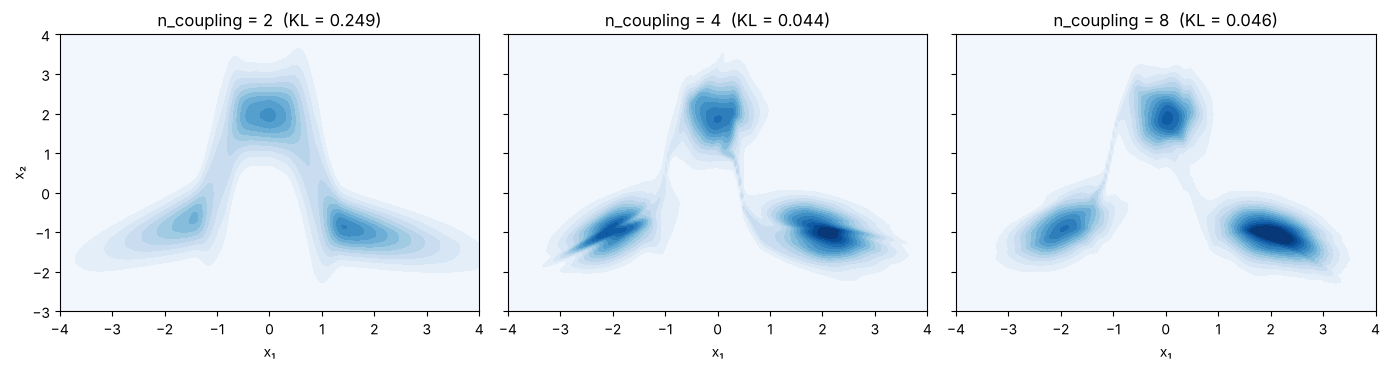

n_coupling | KL(p || q) | KS(x₁)
         2 |     0.2485 | 0.091
         4 |     0.0442 | 0.020
         8 |     0.0458 | 0.028


In [8]:
sweep = {}
for nc in [2, 4, 8]:
    tf.keras.utils.set_random_seed(0)
    m = build_model("realnvp", x_dim=2, n_coupling=nc)
    fit_model(m, x_gm, epochs=60, **FIT)
    logq = m.log_prob(x_gm_test).numpy()
    dens = np.exp(m.log_prob(xy_grid).numpy()).reshape(gx.shape)
    s = m.sample(10_000).numpy()
    sweep[nc] = dict(kl=kl_estimate(mixture_logpdf(x_gm_test), logq), ks=ks_statistic(s[:, 0], mixture_marginal_cdf), dens=dens)

fig, axes = plt.subplots(1, len(sweep), figsize=(14, 3.8), sharey=True)
for ax, (nc, r) in zip(axes, sweep.items()):
    ax.contourf(gx, gy, np.minimum(r["dens"], levels[-1]), levels=levels, cmap="Blues")
    ax.set(title=f"n_coupling = {nc}  (KL = {r['kl']:.3f})", xlabel="x₁")
axes[0].set_ylabel("x₂")
fig.tight_layout()
plt.show()

print("n_coupling | KL(p || q) | KS(x₁)")
for nc, r in sweep.items():
    print(f"{nc:10d} | {r['kl']:10.4f} | {r['ks']:.3f}")

**Observation:** With 2 coupling layers the flow cannot separate the mixture (KL ≈ 0.25); from 4 layers on the fit is good (KL ≈ 0.045). Going from 4 to 8 layers brings no further gain at this training length. More layers mainly pay off together with longer training. All KL values here come from a short, untuned training run and can be lowered further.

## 7. Invertibility, Storage and Loading

A normalizing flow is a bijection: `forward` maps data to the latent space (a standard normal), `inverse` maps back.
Both directions share the same weights, and `log_prob = log N(z) + log|det J|`.

In [9]:
z, log_det = crealnvp.forward(v_train[:2000], T_train[:2000])
v_back = crealnvp.inverse(z, T_train[:2000]).numpy()

print("max. reconstruction error |inverse(forward(v)) - v|:", float(np.abs(v_back - v_train[:2000]).max()))
print("latent variables z (should be ~ N(0, 1)): mean", z.numpy().mean(0).round(3), "| std", z.numpy().std(0).round(3))

max. reconstruction error |inverse(forward(v)) - v|: 9.5367431640625e-07
latent variables z (should be ~ N(0, 1)): mean [-0.007  0.023  0.022] | std [1.012 0.994 0.986]


**Observation:** The inverse reproduces the data up to float precision (≈ 1e-6), and the latent variables are close to standard normal, which confirms a consistent forward/inverse pair and a correctly trained flow.

To load the model, a model with **the same architecture** is built and initialized with `warmup()`
(`warmup()` sets all weights without training anything).

In [10]:
path = Path(tempfile.mkdtemp()) / "crealnvp_maxwell.weights.h5"

crealnvp.warmup()
crealnvp.save_weights(str(path))

restored = build_model("crealnvp", x_dim=3, cond_dim=1)
restored.warmup()
restored.load_weights(str(path))

same = all(np.allclose(a, b) for a, b in zip(crealnvp.get_weights(), restored.get_weights()))
print("Weights identical:", same)

Weights identical: True
